In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score



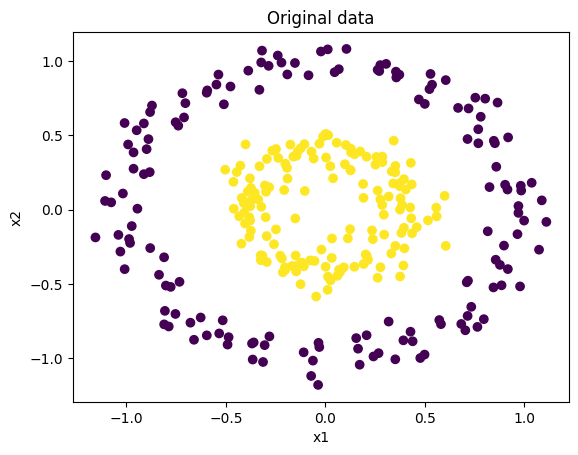

In [2]:
X, y = make_circles(
    n_samples=300,
    noise=0.08,
    factor=0.4, #how small circle is different than bigger
    random_state=42
)

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Original data")
plt.show()

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Use training samples as landmarks
landmarks = X_train

print("Training samples:", X_train.shape[0])
print("Number of landmarks:", landmarks.shape[0])

Training samples: 240
Number of landmarks: 240


In [4]:
def gaussian_similarity(X, landmarks, sigma=0.3):
    # Calculate squared distance from each sample to each landmark
    distances_squared = np.sum(
        (X[:, None, :] - landmarks[None, :, :])**2,# [240,1,2] 240x1 matrix, final matrix through broadcasting is 240x24
        #240x240 matrix after dimensionality conversion
        axis=2
    )

    # Convert distances into similarity features
    return np.exp(-distances_squared / (2 * sigma**2))

In [5]:
# Transform training and testing data
X_train_kernel = gaussian_similarity(
    X_train, landmarks, sigma=0.3
)

X_test_kernel = gaussian_similarity(
    X_test, landmarks, sigma=0.3
)

print("Original training shape:", X_train.shape)
print("Transformed training shape:", X_train_kernel.shape)

Original training shape: (240, 2)
Transformed training shape: (240, 240)


In [6]:
svm_landmarks = SVC(kernel="linear")

svm_landmarks.fit(X_train_kernel, y_train)

y_pred = svm_landmarks.predict(X_test_kernel)

print("Landmark-feature SVM accuracy:",
      accuracy_score(y_test, y_pred))

Landmark-feature SVM accuracy: 1.0


In [7]:
svm_rbf = SVC(
    kernel="rbf",
    gamma=1 / (2 * 0.3**2)
)

svm_rbf.fit(X_train, y_train)

y_pred_rbf = svm_rbf.predict(X_test)

print("Built-in RBF SVM accuracy:",
      accuracy_score(y_test, y_pred_rbf))

Built-in RBF SVM accuracy: 1.0


In [11]:
def plot_boundary(model, X, y, transform=None, title=""):
    x_min, x_max = X[:, 0].min() - 0.2, X[:, 0].max() + 0.2
    y_min, y_max = X[:, 1].min() - 0.2, X[:, 1].max() + 0.2

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]#

    if transform is not None:
        grid_features = transform(grid, landmarks, sigma=0.3)
    else:
        grid_features = grid

    Z = model.predict(grid_features).reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.25)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k", s=20)
    plt.title(title)
    plt.show()

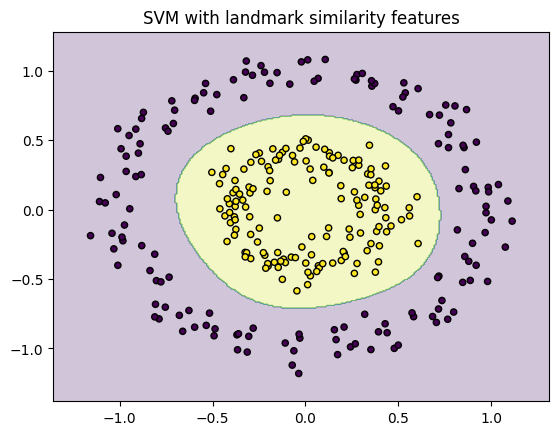

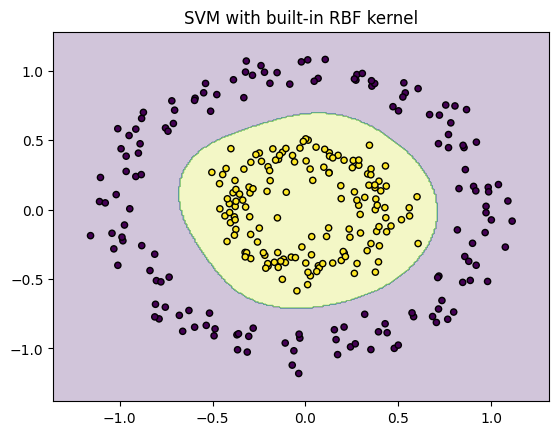

In [10]:
plot_boundary(
    svm_landmarks, X, y,
    transform=gaussian_similarity,
    title="SVM with landmark similarity features"
)

plot_boundary(
    svm_rbf, X, y,
    title="SVM with built-in RBF kernel"
)